In [1]:
%load_ext autoreload
%autoreload 2

# 1. IMPORT LIBRARIES AND SET STATIC VARIABLES

In [26]:
import pandas as pd
import numpy as np
# Plot Cumulative Returns
import matplotlib.pyplot as plt
from fredapi import Fred
import yfinance as yf
from scipy.optimize import minimize
import os

In [3]:
FED_API_KEY="79b300c57b4893f902328303a135d4a1"

# 2.INITIALIZE DATA 

In [4]:
import google.auth
from google.auth.transport.requests import AuthorizedSession

SHEET_ID = "1XKeBA6hcnPLcdPixX5bWBtbDTBWP-MtK7Av8ead0NN0"

credentials, _ = google.auth.default(
    scopes=["https://www.googleapis.com/auth/drive.readonly"]
)

print("Identité :", getattr(credentials, "service_account_email", "Autre"))

session = AuthorizedSession(credentials)

response = session.get(
    f"https://www.googleapis.com/drive/v3/files/{SHEET_ID}/export",
    params={
        "mimeType": "application/vnd.openxmlformats-officedocument.spreadsheetml.sheet"
    },
    timeout=120
)

print("HTTP :", response.status_code)
print("Réponse Google :", response.text[:2000] if not response.ok else "Accès OK")

Identité : 200307969304-compute@developer.gserviceaccount.com
HTTP : 200
Réponse Google : Accès OK


In [136]:
STRATEGY_SHEET_ID = '1XKeBA6hcnPLcdPixX5bWBtbDTBWP-MtK7Av8ead0NN0'

def reload_strategy_excel():
    credentials, _ = google.auth.default(
        scopes=['https://www.googleapis.com/auth/drive.readonly']
    )

    session = AuthorizedSession(credentials)

    response = session.get(
        f'https://www.googleapis.com/drive/v3/files/{STRATEGY_SHEET_ID}/export',
        params={
            'mimeType': 'application/vnd.openxmlformats-officedocument.spreadsheetml.sheet'
        },
        timeout=120
    )

    response.raise_for_status()

    print("STRATEGY_ANALYSIS rechargé avec succès")
    return BytesIO(response.content)

In [119]:
# Source : Google Sheets privé STRATEGY_ANALYSIS (authentification Google sur le Mac)
# Prérequis : pip install google-auth requests openpyxl
# Première connexion : gcloud auth application-default login --scopes=https://www.googleapis.com/auth/drive.readonly,https://www.googleapis.com/auth/cloud-platform
from io import BytesIO
import google.auth
from google.auth.transport.requests import AuthorizedSession

STRATEGY_SHEET_ID = '1XKeBA6hcnPLcdPixX5bWBtbDTBWP-MtK7Av8ead0NN0'
credentials, _ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
session = AuthorizedSession(credentials)
response = session.get(
    f'https://www.googleapis.com/drive/v3/files/{STRATEGY_SHEET_ID}/export',
    params={'mimeType': 'application/vnd.openxmlformats-officedocument.spreadsheetml.sheet'},
    timeout=120,
)
response.raise_for_status()
strategy_excel = BytesIO(response.content)

data = pd.read_excel(strategy_excel, sheet_name='EQUITY BACKTEST STRATEGY', skiprows=3, usecols=[0, 1, 4])

In [120]:
data

,Date,Close,Close.1
0,1998-12-31 16:00:00.288,1229.40,1.16800
1,1999-01-08 16:00:00.288,1275.09,1.15800
2,1999-01-14 16:00:00.288,1212.19,1.15600
3,1999-01-22 16:00:00.288,1225.19,1.15850
4,1999-01-29 16:00:00.288,1279.64,1.13650
...,...,...,...
1446,2026-10-09 16:00:00.288,7811.54,1.14790
1447,2026-10-16 16:00:00.288,7659.44,1.13900
1448,NaT,NaN,1.12560
1449,NaT,NaN,1.12020


In [121]:
def convert_df_date(data):
    # Format the 'Date' column to show only the date (YYYY-MM-DD)
    data['Date'] = data['Date'].dt.strftime('%Y-%m-%d')
    # Set 'Date' as the index

    data.index=pd.to_datetime(data.index, errors='coerce')
    return data

In [122]:
# Format the 'Date' column to show only the date (YYYY-MM-DD)
data['Date'] = data['Date'].dt.strftime('%Y-%m-%d')
# Set 'Date' as the index
data.set_index('Date', inplace=True)
data.index=pd.to_datetime(data.index, errors='coerce')

# Rename columns 'Close' to 'SPX' and 'Close.1' to 'EURUSD'
data.rename(columns={'Close': 'SPX', 'Close.1': 'EURUSD'}, inplace=True)
data.dropna(inplace=True)

In [123]:
data.index

DatetimeIndex(['1998-12-31', '1999-01-08', '1999-01-14', '1999-01-22',
               '1999-01-29', '1999-02-05', '1999-02-12', '1999-02-19',
               '1999-02-26', '1999-03-05',
               ...
               '2026-08-14', '2026-08-21', '2026-08-28', '2026-09-04',
               '2026-09-11', '2026-09-18', '2026-09-25', '2026-10-02',
               '2026-10-09', '2026-10-16'],
              dtype='datetime64[ns]', name='Date', length=1448, freq=None)

In [124]:
# Assuming the DataFrame is called 'data', and it contains the 'SPX' column
DVIDEND_YIELD = 0.02  # Example: 2% annual dividend yield
initial_value = data['SPX'].iloc[0]  # Assume SPXTR starts equal to the first value of SPX

# Create SPXTR column and initialize the first value
data['SPXTR'] = 0
data.loc[data.index[0], 'SPXTR'] = initial_value

# Loop over rows to calculate SPXTR based on the formula provided
for i in range(1, len(data)):
    data.loc[data.index[i], 'SPXTR'] = data.loc[data.index[i-1], 'SPXTR'] * (
        1 + (data.loc[data.index[i], 'SPX'] - data.loc[data.index[i-1], 'SPX']) / data.loc[data.index[i-1], 'SPX'] 
        + DVIDEND_YIELD / 52
    )


/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn/T/ipykernel_46610/309903971.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '1229.4' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  data.loc[data.index[0], 'SPXTR'] = initial_value


In [125]:
data

,SPX,EURUSD,SPXTR
Date,,,
1998-12-31,1229.40,1.1680,1229.400000
1999-01-08,1275.09,1.1580,1275.562846
1999-01-14,1212.19,1.1560,1213.130122
1999-01-22,1225.19,1.1585,1226.606793
1999-01-29,1279.64,1.1365,1281.591530
...,...,...,...
2026-09-18,7650.50,1.1582,13318.211021
2026-09-25,7743.41,1.1613,13485.073817
2026-10-02,7722.72,1.1601,13454.228949


In [126]:
# Create the TRCompo column by dividing SPXTR by EURUSD
data['TRCompo'] = data['SPXTR'] / data['EURUSD']

In [13]:
data

,SPX,EURUSD,SPXTR,TRCompo
Date,,,,
1998-12-31,1229.40,1.1680,1229.400000,1052.568493
1999-01-08,1275.09,1.1580,1275.562846,1101.522320
1999-01-14,1212.19,1.1560,1213.130122,1049.420521
1999-01-22,1225.19,1.1585,1226.606793,1058.788772
1999-01-29,1279.64,1.1365,1281.591530,1127.665226
...,...,...,...,...
2026-09-18,7650.50,1.1582,13318.211021,11499.059766
2026-09-25,7743.41,1.1613,13485.073817,11612.050131
2026-10-02,7722.72,1.1601,13454.228949,11597.473449


In [14]:
# Calculate returns for each column
data['SPX_return'] = data['SPX'].pct_change()  # Percentage change for SPX
data['USDEUR_return'] = -data['EURUSD'].pct_change()  # Percentage change for EURUSD
data['SPXTR_return'] = data['SPXTR'].pct_change()  # Percentage change for SPXTR
data['TRCompo_return'] = data['TRCompo'].pct_change()  # Percentage change for SPXTR
data.dropna(inplace=True)
# Calculate standard deviation of returns
spx_std = round(data['SPX_return'].std()*100*np.sqrt(52),2)
eurusd_std = round(data['USDEUR_return'].std()*100*np.sqrt(52),2)
spxtr_std = round(data['SPXTR_return'].std()*100*np.sqrt(52),2)
spxtr_compo_std = round(data['TRCompo_return'].std()*100*np.sqrt(52),2)

# Print the standard deviations
print(f"Standard deviation of SPX returns: {spx_std}")
print(f"Standard deviation of EURUSD returns: {eurusd_std}")
print(f"Standard deviation of SPXTR returns: {spxtr_std}")
print(f"Standard deviation of SPXTR Composite EURO returns: {spxtr_compo_std}")

Standard deviation of SPX returns: 17.68
Standard deviation of EURUSD returns: 9.23
Standard deviation of SPXTR returns: 17.68
Standard deviation of SPXTR Composite EURO returns: 19.26


In [15]:
# seta weekly crash flag
ALPHA=-0.1
data['Crash'] = data['SPX_return'] < ALPHA

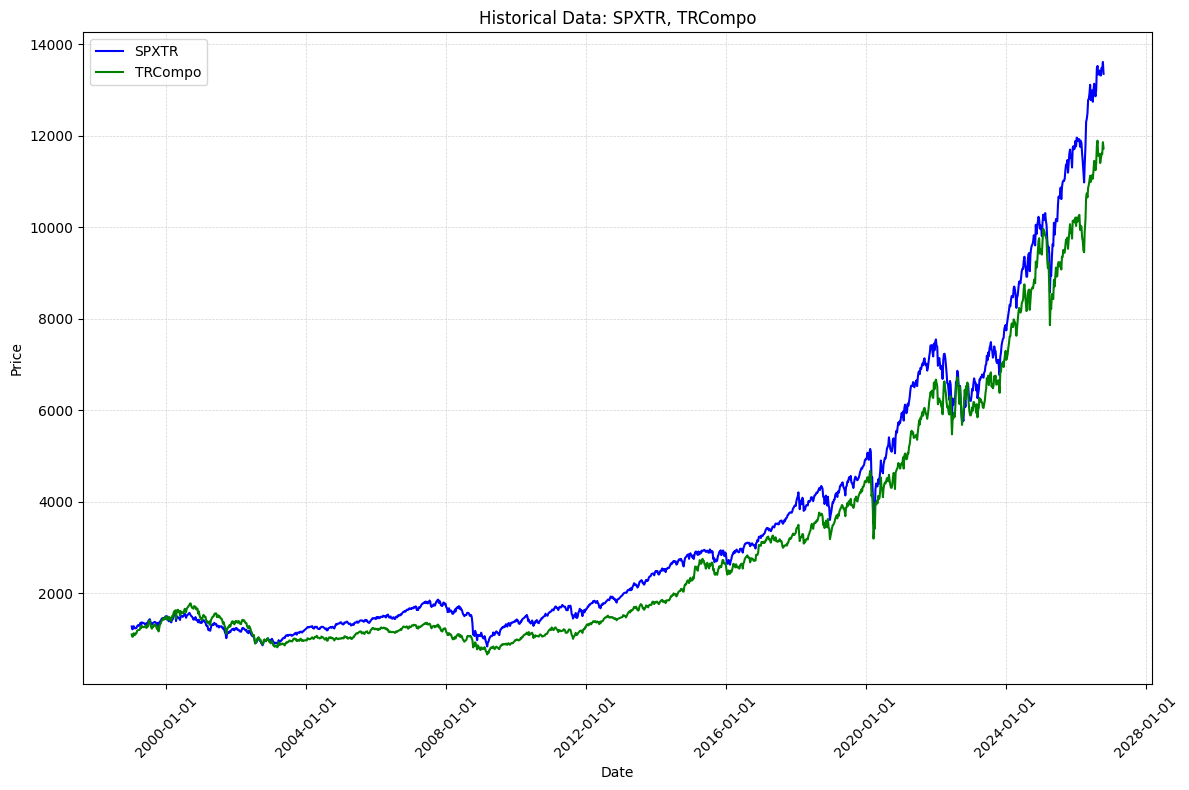

In [16]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

# Set plot style
plt.style.use('default')

# Plot the data
plt.figure(figsize=(12, 8))
plt.plot(data.index, data['SPXTR'], label='SPXTR', color='blue')
plt.plot(data.index, data['TRCompo'], label='TRCompo', color='green')

# Format the x-axis for dates
plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator())  # Automatically choose appropriate ticks
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # Format as 'YYYY-MM-DD'

# Rotate x-axis labels for readability
plt.xticks(rotation=45)

# Add labels, title, and legend
plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Historical Data: SPXTR, TRCompo')
plt.legend()

# Add gridlines
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Show the plot
plt.tight_layout()  # Adjust layout to prevent label clipping
plt.show()


In [17]:
data.describe()

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return
count,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000
mean,2382.201216,1.182111,3499.034993,3057.772579,0.001568,-0.000065,0.001953,0.002026
std,1651.964077,0.151120,3000.580859,2704.020674,0.024517,0.012798,0.024517,0.026709
min,683.380000,0.837200,838.442584,663.587324,-0.181955,-0.053917,-0.181570,-0.163427
25%,1230.265000,1.086950,1385.506734,1157.616128,-0.010620,-0.007921,-0.010235,-0.012547
50%,1520.770000,1.167800,1898.123264,1629.162209,0.002729,0.000000,0.003113,0.002625
75%,2966.030000,1.294650,4502.276047,4053.730281,0.014530,0.007770,0.014915,0.017174
max,7811.540000,1.594100,13614.142477,11893.396249,0.121017,0.058552,0.121402,0.161106


In [18]:
# Define the window for 5 years (assuming monthly data, this is 60 months)
WINDOW_SIZE = 260

In [19]:
# Create an empty DataFrame for storing the rolling performance
rolling_performance_5Y = pd.DataFrame(index=data.index)

# Loop through the data, starting at the index equal to WINDOW_SIZE
for i in range(WINDOW_SIZE, len(data)):
    # Use the actual Date-based index, not the integer index
    rolling_performance_5Y.loc[data.index[i], 'Rolling5YPerf'] =round( 100* ( data.loc[data.index[i], 'TRCompo'] 
                                                                      / data.loc[data.index[i-WINDOW_SIZE], 'TRCompo'] - 1),2)


rolling_performance_5Y.dropna(inplace=True)




In [20]:
rolling_performance_5Y.describe()

,Rolling5YPerf
count,1187.000000
mean,62.516125
std,59.805251
min,-38.810000
25%,-1.380000
50%,86.080000
75%,111.445000
max,184.990000


In [21]:
rolling_performance_5Y.index

DatetimeIndex(['2004-01-02', '2004-01-09', '2004-01-16', '2004-01-23',
               '2004-01-30', '2004-02-06', '2004-02-13', '2004-02-20',
               '2004-02-27', '2004-03-05',
               ...
               '2026-08-14', '2026-08-21', '2026-08-28', '2026-09-04',
               '2026-09-11', '2026-09-18', '2026-09-25', '2026-10-02',
               '2026-10-09', '2026-10-16'],
              dtype='datetime64[ns]', name='Date', length=1187, freq=None)

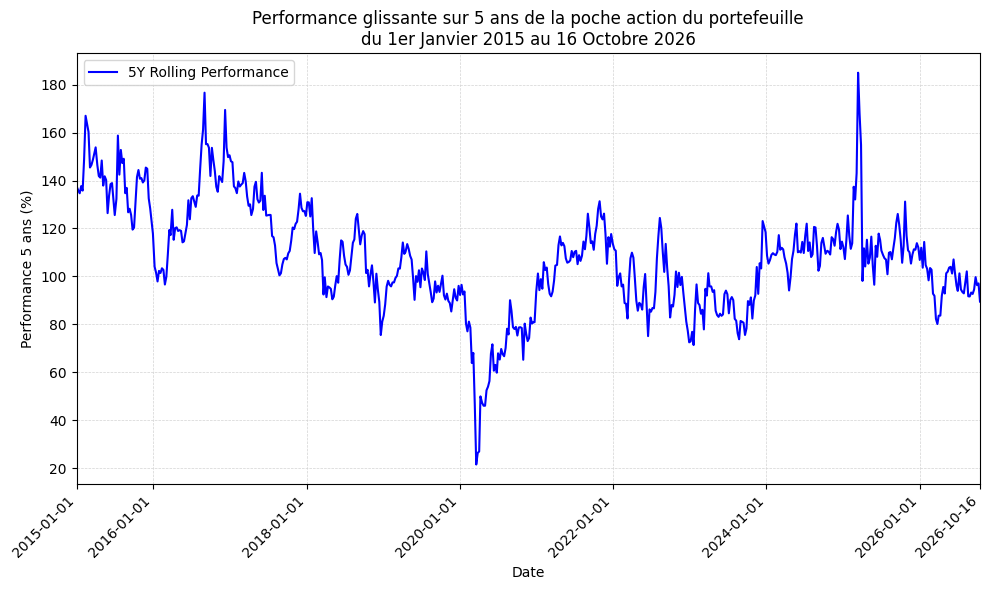

In [44]:
# Ensure the index is a datetime object
rolling_performance_5Y.index = pd.to_datetime(rolling_performance_5Y.index)

# Filtrer les données à partir du 01/01/2015
date_debut = pd.Timestamp('2015-01-01')

data_plot = rolling_performance_5Y.loc[
    rolling_performance_5Y.index >= date_debut
].sort_index()

if data_plot.empty:
    raise ValueError("Aucune donnée disponible à partir du 01/01/2015")

# Dernière date disponible
date_fin = data_plot.index.max()

# Plot the 5-year rolling performance
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    data_plot.index,
    data_plot['Rolling5YPerf'],
    label='5Y Rolling Performance',
    color='blue'
)

# Titre avec dates de début et de fin
mois_fr = [
    "Janvier", "Février", "Mars", "Avril", "Mai", "Juin",
    "Juillet", "Août", "Septembre", "Octobre", "Novembre", "Décembre"
]

def format_date_fr(date):
    jour = "1er" if date.day == 1 else str(date.day)
    return f"{jour} {mois_fr[date.month - 1]} {date.year}"

ax.set_title(
    f'Performance glissante sur 5 ans de la poche action du portefeuille\n'
    f'du {format_date_fr(date_debut)} au {format_date_fr(date_fin)}'
)

ax.set_xlabel('Date')
ax.set_ylabel('Performance 5 ans (%)')
ax.legend()

# Axe X : limites exactes
ax.set_xlim(date_debut, date_fin)

# Graduations automatiques + dates extrêmes
locator = mdates.AutoDateLocator()
ticks = locator.tick_values(date_debut, date_fin)

debut_num = mdates.date2num(date_debut)
fin_num = mdates.date2num(date_fin)

ticks = ticks[(ticks > debut_num) & (ticks < fin_num)]
ticks = np.concatenate(([debut_num], ticks, [fin_num]))

ax.set_xticks(ticks)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

plt.xticks(rotation=45, ha='right')

# Grille
ax.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Enregistrer le graphique
plt.tight_layout()

os.makedirs("./results", exist_ok=True)

plt.savefig(
    "./results/5Y_SPX_Roll.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
rolling_performance_5Y_filtered = rolling_performance_5Y.loc[
    pd.to_datetime(rolling_performance_5Y.index) >= '2015-01-01'
].copy()

In [33]:
# Calculate the standard deviation of returns for each column
annual_volatility = round(
    rolling_performance_5Y_filtered['Rolling5YPerf'].std() / np.sqrt(5),
    2
)
annualized_median_return = round(float(rolling_performance_5Y_filtered.median().iloc[0]/5),2)
annualized_mean_return = round(float(rolling_performance_5Y_filtered.mean().iloc[0]/5),2)

# Display the standard deviation of returns
print(f"Annualized volatility of strategy: {annual_volatility}%")
print(f"Annualized Median Return of strategy: {annualized_median_return}%")
print(f"Annualized Mean Return of strategy: {annualized_mean_return}%")



Annualized volatility of strategy: 10.04%
Annualized Median Return of strategy: 21.43%
Annualized Mean Return of strategy: 21.54%


In [34]:
annual_volatility

10.04

In [35]:
OBLIG_RETURN=6
OBLIG_RATIO=0.6
combo_return= OBLIG_RATIO * OBLIG_RETURN + (1-OBLIG_RATIO)  * annualized_median_return
combo_return

12.172

In [36]:
combo_vol = round((1-OBLIG_RATIO)  * annual_volatility,2)
sharp_ratio=round(combo_return/combo_vol,2)

In [37]:
combo_return,combo_vol, sharp_ratio

(12.172, 4.02, 3.03)

# ANALYSE DE LA CORRELATION entre S&P et EURUSD en crash de marche

In [38]:
# Assuming 'data' is your DataFrame, and you want to calculate correlation between 'Column1' and 'Column2'
correlation = round(data['SPX_return'].corr(data['USDEUR_return'])*100,2)

In [39]:
print(f"Correlation S&P vs EURUSD FX: {correlation}%")

Correlation S&P vs EURUSD FX: -8.35%


In [40]:
data

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,Crash
Date,,,,,,,,,
1999-01-08,1275.09,1.1580,1275.562846,1101.522320,0.037164,0.008562,0.037549,0.046509,False
1999-01-14,1212.19,1.1560,1213.130122,1049.420521,-0.049330,0.001727,-0.048945,-0.047300,False
1999-01-22,1225.19,1.1585,1226.606793,1058.788772,0.010724,-0.002163,0.011109,0.008927,False
1999-01-29,1279.64,1.1365,1281.591530,1127.665226,0.044442,0.018990,0.044827,0.065052,False
1999-02-05,1239.40,1.1257,1241.783081,1103.120797,-0.031446,0.009503,-0.031062,-0.021766,False
...,...,...,...,...,...,...,...,...,...
2026-09-18,7650.50,1.1582,13318.211021,11499.059766,-0.000846,0.008645,-0.000462,0.008255,False
2026-09-25,7743.41,1.1613,13485.073817,11612.050131,0.012144,-0.002677,0.012529,0.009826,False
2026-10-02,7722.72,1.1601,13454.228949,11597.473449,-0.002672,0.001033,-0.002287,-0.001255,False


In [41]:
# Filter the data where Crash is True
filtered_data = data[data['Crash'] == True]

# Calculate the correlation between the two columns on the filtered data
correlation = round(filtered_data['SPX_return'].corr(filtered_data['USDEUR_return'])*100,2)

# Display the correlation
print(f"Correlation between S&P and USDEUR FX during crashes: {correlation}%")


Correlation between S&P and USDEUR FX during crashes: -39.85%


# COMPARISON vs. SX5E

In [64]:
data_SX5E = pd.read_excel(
    strategy_excel,
    sheet_name='vsSTOXX50E',
    skiprows=3,
    usecols=[0, 1, 4, 7]
)

# Renommer les colonnes
data_SX5E.rename(
    columns={
        'Close': 'SPX',
        'Close.1': 'EURUSD',
        'Close.2': 'SX5E'
    },
    inplace=True
)

# Convertir les dates
data_SX5E['Date'] = pd.to_datetime(
    data_SX5E['Date'], errors='coerce'
)

# Convertir les valeurs en nombres
for col in ['SPX', 'EURUSD', 'SX5E']:
    data_SX5E[col] = pd.to_numeric(data_SX5E[col], errors='coerce')

# Nettoyer et indexer
data_SX5E.dropna(inplace=True)
data_SX5E.set_index('Date', inplace=True)
data_SX5E.sort_index(inplace=True)
data_SX5E = data_SX5E.loc['2015-01-01':].copy()
print(data_SX5E.head())

                             SPX  EURUSD     SX5E
Date                                             
2015-01-02 16:00:00.288  2058.20  1.2462  3067.32
2015-01-09 16:00:00.288  2044.81  1.2227  3141.28
2015-01-16 16:00:00.288  2019.42  1.2181  3184.66
2015-01-23 16:00:00.288  2051.82  1.1998  3139.44
2015-01-30 16:00:00.288  1994.99  1.1838  3042.90


In [65]:
data_SX5E

,SPX,EURUSD,SX5E
Date,,,
2015-01-02 16:00:00.288,2058.20,1.2462,3067.32
2015-01-09 16:00:00.288,2044.81,1.2227,3141.28
2015-01-16 16:00:00.288,2019.42,1.2181,3184.66
2015-01-23 16:00:00.288,2051.82,1.1998,3139.44
2015-01-30 16:00:00.288,1994.99,1.1838,3042.90
...,...,...,...
2026-09-18 16:00:00.288,7650.50,1.1582,6325.13
2026-09-25 16:00:00.288,7743.41,1.1613,6236.20
2026-10-02 16:00:00.288,7722.72,1.1601,6302.82


In [66]:
data_SX5E['SPX_EUR'] = data_SX5E['SPX'] / data_SX5E['EURUSD']

In [67]:
data_SX5E.tail(20)

,SPX,EURUSD,SX5E,SPX_EUR
Date,,,,
2026-06-05 16:00:00.288,7383.74,1.16260,6050.54,6351.057974
2026-06-12 16:00:00.288,7431.46,1.16030,6062.07,6404.774627
2026-06-18 16:00:00.288,7500.58,1.16607,6187.63,6432.358263
2026-06-26 16:00:00.288,7354.02,1.15201,6293.13,6383.642503
2026-07-02 16:00:00.288,7483.24,1.15680,6221.55,6468.914246
2026-07-10 16:00:00.288,7575.39,1.14710,6412.68,6603.949089
2026-07-17 16:00:00.288,7457.69,1.13880,6269.97,6548.726730
2026-07-24 16:00:00.288,7411.98,1.14350,6230.87,6481.836467
2026-07-31 16:00:00.288,7489.72,1.14140,6280.94,6561.871386


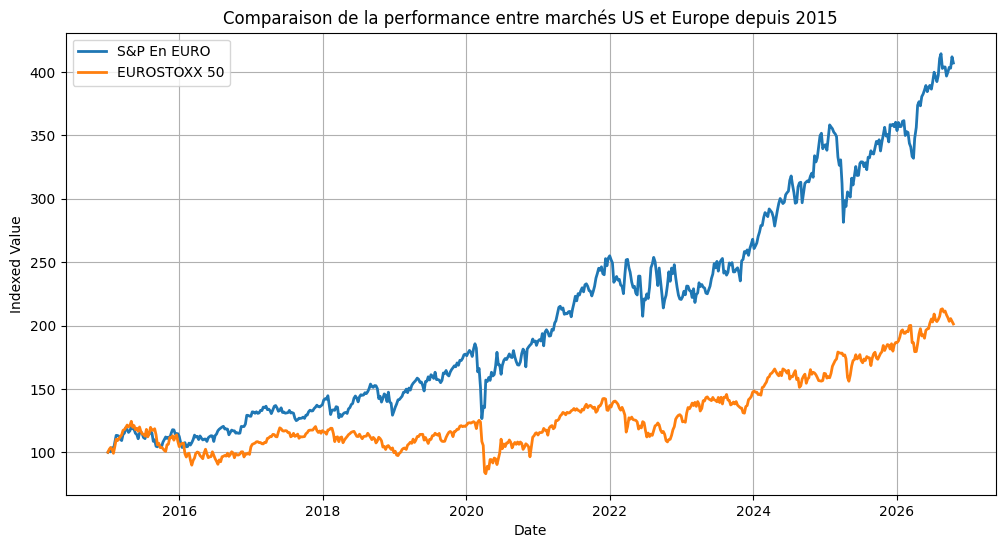

In [70]:
# Normalize both SPX_EUR and SX5E to start at 100
data_SX5E["SPX_EUR_Indexed"] = (data_SX5E["SPX_EUR"] / data_SX5E["SPX_EUR"].iloc[0]) * 100
data_SX5E["SX5E_Indexed"] = (data_SX5E["SX5E"] / data_SX5E["SX5E"].iloc[0]) * 100

# Plot the indexed values
plt.figure(figsize=(12, 6))
plt.plot(data_SX5E.index, data_SX5E["SPX_EUR_Indexed"], label="S&P En EURO", linewidth=2)
plt.plot(data_SX5E.index, data_SX5E["SX5E_Indexed"], label="EUROSTOXX 50", linewidth=2)
plt.title("Comparaison de la performance entre marchés US et Europe depuis 2015")
plt.xlabel("Date")
plt.ylabel("Indexed Value")
plt.legend()
plt.grid()
plt.savefig("./results/SPXvSSX5E.png", dpi=300, bbox_inches="tight")
plt.show()


# 3. GET HISTORICAL FED DATA FOR TBILL

In [71]:
# Replace 'your_api_key' with your actual FRED API key
fred = Fred(api_key=FED_API_KEY)

# Example: Fetching the 5-Year Treasury Constant Maturity Rate ('DGS5')
tbill_5y_data = fred.get_series('DGS5')

In [72]:
tbill_5y_data

1962-01-02    3.88
1962-01-03    3.87
1962-01-04    3.86
1962-01-05    3.89
1962-01-08    3.91
              ... 
2026-10-16    4.89
2026-10-19    4.94
2026-10-20    4.94
2026-10-21    4.95
2026-10-22    4.78
Length: 16908, dtype: float64

In [73]:
tbill_5y_data.index = pd.to_datetime(tbill_5y_data.index)

In [74]:
tbill_5y_data.dropna(inplace=True)

In [75]:
# Convert Series to DataFrame
tbill_5y_df = pd.DataFrame(tbill_5y_data)

# Optionally, rename the column for clarity
tbill_5y_df.rename(columns={tbill_5y_df.columns[0]: '5Y_TBill_Yield'}, inplace=True)


In [76]:
data.index=pd.to_datetime(data.index)

In [77]:
# Perform a left join to match the dates in the original time series with the T-Bill data
matched_data = data.join(tbill_5y_df, how='left')

In [78]:
matched_data

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,Crash,5Y_TBill_Yield
Date,,,,,,,,,,
1999-01-08,1275.09,1.1580,1275.562846,1101.522320,0.037164,0.008562,0.037549,0.046509,False,4.72
1999-01-14,1212.19,1.1560,1213.130122,1049.420521,-0.049330,0.001727,-0.048945,-0.047300,False,4.48
1999-01-22,1225.19,1.1585,1226.606793,1058.788772,0.010724,-0.002163,0.011109,0.008927,False,4.54
1999-01-29,1279.64,1.1365,1281.591530,1127.665226,0.044442,0.018990,0.044827,0.065052,False,4.55
1999-02-05,1239.40,1.1257,1241.783081,1103.120797,-0.031446,0.009503,-0.031062,-0.021766,False,4.88
...,...,...,...,...,...,...,...,...,...,...
2026-09-18,7650.50,1.1582,13318.211021,11499.059766,-0.000846,0.008645,-0.000462,0.008255,False,4.86
2026-09-25,7743.41,1.1613,13485.073817,11612.050131,0.012144,-0.002677,0.012529,0.009826,False,4.98
2026-10-02,7722.72,1.1601,13454.228949,11597.473449,-0.002672,0.001033,-0.002287,-0.001255,False,5.06


In [79]:
tbill_5y_data.tail(50)

2026-08-12    4.38
2026-08-13    4.32
2026-08-14    4.36
2026-08-17    4.38
2026-08-18    4.37
2026-08-19    4.35
2026-08-20    4.39
2026-08-21    4.43
2026-08-24    4.41
2026-08-25    4.35
2026-08-26    4.37
2026-08-27    4.38
2026-08-28    4.48
2026-08-31    4.49
2026-09-01    4.55
2026-09-02    4.54
2026-09-03    4.52
2026-09-04    4.54
2026-09-08    4.57
2026-09-09    4.61
2026-09-10    4.75
2026-09-11    4.78
2026-09-14    4.80
2026-09-15    4.83
2026-09-16    4.86
2026-09-17    4.78
2026-09-18    4.86
2026-09-21    4.83
2026-09-22    4.83
2026-09-23    4.99
2026-09-24    5.03
2026-09-25    4.98
2026-09-28    5.06
2026-09-29    5.06
2026-09-30    5.09
2026-10-01    5.01
2026-10-02    5.06
2026-10-05    5.06
2026-10-06    5.03
2026-10-07    5.03
2026-10-08    4.99
2026-10-09    5.02
2026-10-13    5.00
2026-10-14    5.00
2026-10-15    4.91
2026-10-16    4.89
2026-10-19    4.94
2026-10-20    4.94
2026-10-21    4.95
2026-10-22    4.78
dtype: float64

In [80]:
data
data.index

DatetimeIndex(['1999-01-08', '1999-01-14', '1999-01-22', '1999-01-29',
               '1999-02-05', '1999-02-12', '1999-02-19', '1999-02-26',
               '1999-03-05', '1999-03-12',
               ...
               '2026-08-14', '2026-08-21', '2026-08-28', '2026-09-04',
               '2026-09-11', '2026-09-18', '2026-09-25', '2026-10-02',
               '2026-10-09', '2026-10-16'],
              dtype='datetime64[ns]', name='Date', length=1447, freq=None)

In [81]:
data.columns

Index(['SPX', 'EURUSD', 'SPXTR', 'TRCompo', 'SPX_return', 'USDEUR_return',
       'SPXTR_return', 'TRCompo_return', 'Crash'],
      dtype='object')

In [82]:
# Define the bond duration
DURATION = 5

# Calculate daily yield changes
matched_data['Yield_Change'] = matched_data['5Y_TBill_Yield'].diff()

# Calculate daily MTM move based on duration and yield change
matched_data['5Y_TBILL_MTM_Move'] = -DURATION * matched_data['Yield_Change']

In [83]:
matched_data.dropna(inplace=True)

In [84]:
matched_data

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,Crash,5Y_TBill_Yield,Yield_Change,5Y_TBILL_MTM_Move
Date,,,,,,,,,,,,
1999-01-14,1212.19,1.1560,1213.130122,1049.420521,-0.049330,0.001727,-0.048945,-0.047300,False,4.48,-0.24,1.20
1999-01-22,1225.19,1.1585,1226.606793,1058.788772,0.010724,-0.002163,0.011109,0.008927,False,4.54,0.06,-0.30
1999-01-29,1279.64,1.1365,1281.591530,1127.665226,0.044442,0.018990,0.044827,0.065052,False,4.55,0.01,-0.05
1999-02-05,1239.40,1.1257,1241.783081,1103.120797,-0.031446,0.009503,-0.031062,-0.021766,False,4.88,0.33,-1.65
1999-02-12,1230.14,1.1303,1232.982885,1090.845691,-0.007471,-0.004086,-0.007087,-0.011128,False,4.96,0.08,-0.40
...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-18,7650.50,1.1582,13318.211021,11499.059766,-0.000846,0.008645,-0.000462,0.008255,False,4.86,0.08,-0.40
2026-09-25,7743.41,1.1613,13485.073817,11612.050131,0.012144,-0.002677,0.012529,0.009826,False,4.98,0.12,-0.60
2026-10-02,7722.72,1.1601,13454.228949,11597.473449,-0.002672,0.001033,-0.002287,-0.001255,False,5.06,0.08,-0.40


In [85]:
matched_data.describe()

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,5Y_TBill_Yield,Yield_Change,5Y_TBILL_MTM_Move
count,1434.000000,1434.000000,1434.000000,1434.000000,1434.000000,1434.000000,1434.000000,1434.000000,1434.000000,1434.000000,1434.000000
mean,2387.630976,1.182587,3508.760964,3065.043463,0.001561,-0.000045,0.001945,0.002039,2.913375,0.000307,-0.001534
std,1655.709799,0.151110,3007.456161,2709.182879,0.024300,0.012811,0.024300,0.026566,1.544996,0.126827,0.634134
min,683.380000,0.837200,838.442584,663.587324,-0.181955,-0.053917,-0.181570,-0.163427,0.210000,-0.520000,-3.100000
25%,1230.202500,1.087000,1385.456098,1157.433288,-0.010620,-0.007874,-0.010235,-0.012512,1.610000,-0.080000,-0.350000
50%,1526.250000,1.168050,1927.621044,1635.181640,0.002685,-0.000000,0.003069,0.002613,2.825000,0.000000,-0.000000
75%,2971.845000,1.294850,4505.877762,4059.738273,0.014474,0.007771,0.014859,0.017136,4.140000,0.070000,0.400000
max,7811.540000,1.594100,13614.142477,11893.396249,0.121017,0.058552,0.121402,0.161106,6.770000,0.620000,2.600000


In [86]:
matched_data['5Y_TBILL_CompoEUR_MTM_Move'] = (1+ matched_data['USDEUR_return'])*(1+matched_data['5Y_TBILL_MTM_Move'])-1

In [87]:
matched_data

,SPX,EURUSD,SPXTR,TRCompo,SPX_return,USDEUR_return,SPXTR_return,TRCompo_return,Crash,5Y_TBill_Yield,Yield_Change,5Y_TBILL_MTM_Move,5Y_TBILL_CompoEUR_MTM_Move
Date,,,,,,,,,,,,,
1999-01-14,1212.19,1.1560,1213.130122,1049.420521,-0.049330,0.001727,-0.048945,-0.047300,False,4.48,-0.24,1.20,1.203800
1999-01-22,1225.19,1.1585,1226.606793,1058.788772,0.010724,-0.002163,0.011109,0.008927,False,4.54,0.06,-0.30,-0.301514
1999-01-29,1279.64,1.1365,1281.591530,1127.665226,0.044442,0.018990,0.044827,0.065052,False,4.55,0.01,-0.05,-0.031959
1999-02-05,1239.40,1.1257,1241.783081,1103.120797,-0.031446,0.009503,-0.031062,-0.021766,False,4.88,0.33,-1.65,-1.656177
1999-02-12,1230.14,1.1303,1232.982885,1090.845691,-0.007471,-0.004086,-0.007087,-0.011128,False,4.96,0.08,-0.40,-0.402452
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-18,7650.50,1.1582,13318.211021,11499.059766,-0.000846,0.008645,-0.000462,0.008255,False,4.86,0.08,-0.40,-0.394813
2026-09-25,7743.41,1.1613,13485.073817,11612.050131,0.012144,-0.002677,0.012529,0.009826,False,4.98,0.12,-0.60,-0.601071
2026-10-02,7722.72,1.1601,13454.228949,11597.473449,-0.002672,0.001033,-0.002287,-0.001255,False,5.06,0.08,-0.40,-0.399380


In [88]:
matched_data['strategy_return']=OBLIG_RATIO*matched_data['5Y_TBILL_CompoEUR_MTM_Move']+ (1-OBLIG_RATIO)*matched_data['TRCompo_return']

In [89]:
matched_data['strategy_return'].std()*np.sqrt(52)

2.727327077011745

In [90]:
matched_data['strategy_return'].median()*260

1.4959152703193086

In [91]:
matched_data['strategy_return']

Date
1999-01-14    0.703360
1999-01-22   -0.177337
1999-01-29    0.006845
1999-02-05   -1.002412
1999-02-12   -0.245922
                ...   
2026-09-18   -0.233586
2026-09-25   -0.356712
2026-10-02   -0.240130
2026-10-09    0.136628
2026-10-16    0.393107
Name: strategy_return, Length: 1434, dtype: float64

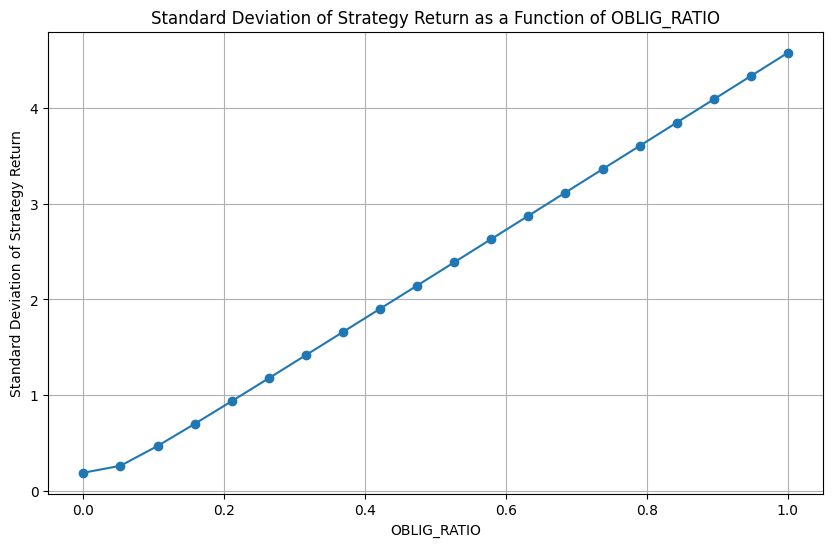

In [92]:
# Define a range of values for OBLIG_RATIO (e.g., from 0 to 1 with 0.1 increments)
oblig_ratios = np.linspace(0, 100, 20)/100
std_dev_values = []

# Loop through each OBLIG_RATIO and calculate the standard deviation of strategy_return
for ratio in oblig_ratios:
    # Calculate the strategy return for the given OBLIG_RATIO
    matched_data['strategy_return'] = (ratio * matched_data['5Y_TBILL_CompoEUR_MTM_Move'] +
                                       (1 - ratio) * matched_data['TRCompo_return'])
    # Calculate the standard deviation of the strategy return and store it
    std_dev_values.append(matched_data['strategy_return'].std()* np.sqrt(52))

# Plot OBLIG_RATIO vs. standard deviation of strategy_return
plt.figure(figsize=(10, 6))
plt.plot(oblig_ratios, std_dev_values, marker='o', linestyle='-')
plt.xlabel('OBLIG_RATIO')
plt.ylabel('Standard Deviation of Strategy Return')
plt.title('Standard Deviation of Strategy Return as a Function of OBLIG_RATIO')
plt.grid(True)
plt.show()

In [93]:
oblig_ratios

array([0.        , 0.05263158, 0.10526316, 0.15789474, 0.21052632,
       0.26315789, 0.31578947, 0.36842105, 0.42105263, 0.47368421,
       0.52631579, 0.57894737, 0.63157895, 0.68421053, 0.73684211,
       0.78947368, 0.84210526, 0.89473684, 0.94736842, 1.        ])

In [94]:
tbill_std = matched_data['5Y_TBILL_CompoEUR_MTM_Move'].std()
trcomp_std = matched_data['TRCompo_return'].std()
print(f"T-Bill Component Std: {tbill_std}, TRCompo Component Std: {trcomp_std}")


T-Bill Component Std: 0.6344056136133659, TRCompo Component Std: 0.026565583151773618


# 3. BACKTEST WITH ETF PORTFOLIO

In [152]:
strategy_excel = reload_strategy_excel()

STRATEGY_ANALYSIS rechargé avec succès


In [155]:
data_etf = pd.read_excel(
    strategy_excel,
    sheet_name='Historique',
    header=None,
    skiprows=4,
    usecols=[0, 1,  5,7]
)

data_etf.columns = ['Date', 'PSP5', 'EURUSD', 'IHYA']

data_etf['Date'] = pd.to_datetime(data_etf['Date'], errors='coerce')

for col in ['PSP5', 'IHYA', 'EURUSD']:
    data_etf[col] = pd.to_numeric(data_etf[col], errors='coerce')

data_etf = data_etf.dropna().sort_values('Date').reset_index(drop=True)

data_etf['IHYA_EUR'] = data_etf['IHYA'] / data_etf['EURUSD']

display(data_etf.head())

,Date,PSP5,EURUSD,IHYA,IHYA_EUR
0,2017-05-05 17:39:59.904,16.79,1.0996,5.03,4.574391
1,2017-05-12 17:39:59.904,16.91,1.0932,5.05,4.619466
2,2017-05-19 17:39:59.904,16.46,1.1207,5.07,4.523958
3,2017-05-26 17:39:59.904,16.71,1.1182,5.08,4.543016
4,2017-06-02 17:39:59.904,16.70,1.1283,5.10,4.520074


In [156]:
perf_etf = data_etf[['Date', 'PSP5', 'IHYA_EUR']].copy()

perf_etf['PSP5'] = perf_etf['PSP5'].pct_change(fill_method=None)
perf_etf['IHYA_EUR'] = perf_etf['IHYA_EUR'].pct_change(fill_method=None)

perf_etf = perf_etf.dropna().reset_index(drop=True)

display(perf_etf.head())

,Date,PSP5,IHYA_EUR
0,2017-05-12 17:39:59.904,0.007147,0.009854
1,2017-05-19 17:39:59.904,-0.026611,-0.020675
2,2017-05-26 17:39:59.904,0.015188,0.004213
3,2017-06-02 17:39:59.904,-0.000598,-0.005050
4,2017-06-09 17:39:59.904,0.011976,0.004177


In [159]:
OBLIG_RATIO = 0.30  # 30 % obligations, 70 % actions

perf_etf['port_perf'] = (
    perf_etf['PSP5'] * (1 - OBLIG_RATIO)
    + perf_etf['IHYA_EUR'] * OBLIG_RATIO
)

perf_etf['ref_index'] = 100 * (1 + perf_etf['port_perf']).cumprod()

In [160]:
perf_etf

,Date,PSP5,IHYA_EUR,port_perf,ref_index
0,2017-05-12 17:39:59.904,0.007147,0.009854,0.007959,100.795912
1,2017-05-19 17:39:59.904,-0.026611,-0.020675,-0.024831,98.293095
2,2017-05-26 17:39:59.904,0.015188,0.004213,0.011896,99.462350
3,2017-06-02 17:39:59.904,-0.000598,-0.005050,-0.001934,99.270006
4,2017-06-09 17:39:59.904,0.011976,0.004177,0.009636,100.226615
...,...,...,...,...,...
488,2026-09-18 17:39:59.904,0.006195,0.006580,0.006311,270.051984
489,2026-09-25 17:39:59.904,0.017787,-0.000292,0.012363,273.390709
490,2026-10-02 17:39:59.904,0.012603,0.002333,0.009522,275.993895
491,2026-10-09 17:39:59.904,0.015931,0.011675,0.014654,280.038336


In [161]:
N = 52

summary = pd.DataFrame(index=['PSP5', 'IHYA_EUR', 'port_perf'])

for col in summary.index:
    r = perf_etf[col].dropna()

    summary.loc[col, 'Mean annualisé'] = (1 + r.mean())**N - 1
    summary.loc[col, 'Median annualisé'] = (1 + r.median())**N - 1
    summary.loc[col, 'Vol annualisée'] = r.std() * np.sqrt(N)

display(summary.style.format("{:.2%}"))

,Mean annualisé,Median annualisé,Vol annualisée
PSP5,15.87%,21.84%,15.63%
IHYA_EUR,4.34%,4.50%,9.28%
port_perf,12.28%,14.38%,12.91%


In [163]:
portfolio_index = perf_etf[['Date', 'ref_index']].copy()

display(portfolio_index.head())
display(portfolio_index.tail())

,Date,ref_index
0,2017-05-12 17:39:59.904,100.795912
1,2017-05-19 17:39:59.904,98.293095
2,2017-05-26 17:39:59.904,99.462350
3,2017-06-02 17:39:59.904,99.270006
4,2017-06-09 17:39:59.904,100.226615


,Date,ref_index
488,2026-09-18 17:39:59.904,270.051984
489,2026-09-25 17:39:59.904,273.390709
490,2026-10-02 17:39:59.904,275.993895
491,2026-10-09 17:39:59.904,280.038336
492,2026-10-16 17:39:59.904,277.002100


## SCENARIOS du portefeuille

## SCENARIO base sur la backtets du poretfeuille

In [192]:
df = perf_etf.sort_values("Date").copy()
df["Date"] = pd.to_datetime(df["Date"])

start = df[["Date", "ref_index"]].dropna().copy()

end = start.rename(columns={
    "Date": "end_date",
    "ref_index": "end_index"
})

start["target_date"] = start["Date"] + pd.DateOffset(years=5)

periods = pd.merge_asof(
    start.sort_values("target_date"),
    end.sort_values("end_date"),
    left_on="target_date",
    right_on="end_date",
    direction="forward",
    tolerance=pd.Timedelta(days=10)
)

periods["return_5y"] = (
    periods["end_index"] / periods["ref_index"] - 1
)

returns = periods["return_5y"].dropna()

scenarios = returns.quantile([0.10, 0.50, 0.90])

scenarios.index = ["Défavorable", "Médian", "Favorable"]

print((scenarios * 100).round(2).astype(str) + " %")


Défavorable     62.1 %
Médian         73.19 %
Favorable      83.99 %
Name: return_5y, dtype: object


## SCENARIO base sur l'abnalyse historique du S&P et de la devise

In [197]:
df = data[["SPXTR", "EURUSD"]].copy()
df.index = pd.to_datetime(df.index)
df = df.sort_index().dropna()

# Fenêtres historiques de 3 ans
periods = df.copy()
periods["target_date"] = periods.index + pd.DateOffset(years=3)

future = df.reset_index().rename(columns={
    df.index.name or "index": "end_date",
    "SPXTR": "SPXTR_end",
    "EURUSD": "EURUSD_end"
})

periods = periods.reset_index().rename(columns={
    df.index.name or "index": "start_date"
})

periods = pd.merge_asof(
    periods.sort_values("target_date"),
    future.sort_values("end_date"),
    left_on="target_date",
    right_on="end_date",
    direction="forward",
    tolerance=pd.Timedelta(days=10)
).dropna()

# Performances cumulées sur 3 ans
periods["actions_usd"] = (
    periods["SPXTR_end"] / periods["SPXTR"] - 1
)

periods["usd_eur"] = (
    periods["EURUSD"] / periods["EURUSD_end"] - 1
)

periods

,start_date,SPXTR,EURUSD,target_date,end_date,SPXTR_end,EURUSD_end,actions_usd,usd_eur
0,1998-12-31,1229.400000,1.1680,2001-12-31,2002-01-04,1245.534653,0.8942,0.013124,0.306195
1,1999-01-08,1275.562846,1.1580,2002-01-08,2002-01-11,1217.427733,0.8919,-0.045576,0.298352
2,1999-01-14,1213.130122,1.1560,2002-01-14,2002-01-18,1198.746142,0.8840,-0.011857,0.307692
3,1999-01-22,1226.606793,1.1585,2002-01-22,2002-01-25,1205.266949,0.8642,-0.017397,0.340546
4,1999-01-29,1281.591530,1.1365,2002-01-29,2002-02-01,1193.946701,0.8617,-0.068387,0.318904
...,...,...,...,...,...,...,...,...,...
1286,2023-09-15,7294.789620,1.0794,2026-09-15,2026-09-18,13318.211021,1.1582,0.825716,-0.068037
1287,2023-09-22,7084.078237,1.0796,2026-09-22,2026-09-25,13485.073817,1.1613,0.903575,-0.070352
1288,2023-09-29,7034.312559,1.0712,2026-09-29,2026-10-02,13454.228949,1.1601,0.912657,-0.076631
1289,2023-10-06,7070.565176,1.0672,2026-10-06,2026-10-09,13614.142477,1.1479,0.925467,-0.070302


In [202]:
# Hypothèse : rendement obligataire 8 % par an
bond_growth = 1.08 ** 3

# Portefeuille 40 % actions / 60 % obligations,
# sans rééquilibrage
periods["port_3y"] = (
    (
        0.4 * (1 + periods["actions_usd"])
        + 0.6 * bond_growth
    )
    * (1 + periods["usd_eur"])
    - 1
)

# Quantiles historiques
q = periods["port_3y"].quantile([0.10, 0.50, 0.90])

scenarios = pd.DataFrame({
    "Performance 3 ans": q.to_numpy(),
    "Annualisée": ((1 + q) ** (1/3) - 1).to_numpy()
}, index=["Défavorable", "Médian", "Favorable"])

print((scenarios * 100).round(2))

             Performance 3 ans  Annualisée
Défavorable              -7.35       -2.51
Médian                   32.09        9.72
Favorable                54.01       15.48


In [204]:

import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------
# 1. Scénarios historiques à 5 ans
# ----------------------------------------

df = perf_etf[["Date", "ref_index"]].copy()
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").dropna()

start = df.copy()
start["target_date"] = start["Date"] + pd.DateOffset(years=5)

end = df.rename(columns={
    "Date": "end_date",
    "ref_index": "end_index"
})

periods_5y = pd.merge_asof(
    start.sort_values("target_date"),
    end.sort_values("end_date"),
    left_on="target_date",
    right_on="end_date",
    direction="forward",
    tolerance=pd.Timedelta(days=10)
).dropna()

returns_5y = (
    periods_5y["end_index"] / periods_5y["ref_index"] - 1
)

q5 = returns_5y.quantile([0.10, 0.50, 0.90])

scenarios_5y = pd.DataFrame({
    "Performance 5 ans": q5.to_numpy(),
    "Annualisée": ((1 + q5) ** (1/5) - 1).to_numpy()
}, index=["Défavorable", "Médian", "Favorable"])


# ----------------------------------------
# 2. Fonction d'export JPEG
# ----------------------------------------

def exporter_scenarios(df, titre, sous_titre, fichier):

    # Récupère automatiquement les colonnes du DataFrame
    tableau = df.copy()

    for col in tableau.columns:
        tableau[col] = tableau[col].map(lambda x: f"{x:+.2%}")

    fig, ax = plt.subplots(figsize=(10, 3.4))
    ax.axis("off")

    table = ax.table(
        cellText=tableau.reset_index().values,
        colLabels=["Scénario"] + list(tableau.columns),
        cellLoc="center",
        colLoc="center",
        bbox=[0.02, 0.16, 0.96, 0.58]
    )

    table.auto_set_font_size(False)
    table.set_fontsize(12)

    for (r, c), cell in table.get_celld().items():
        cell.set_edgecolor("#D9E1EA")
        if r == 0:
            cell.set_facecolor("#17365D")
            cell.set_text_props(color="white", weight="bold")
        else:
            cell.set_facecolor(
                "#F1F5FA" if r % 2 else "white"
            )

    fig.text(
        0.5, 0.92, titre,
        ha="center", fontsize=17,
        weight="bold", color="#17365D"
    )

    fig.text(
        0.5, 0.82, sous_titre,
        ha="center", fontsize=10,
        color="#526477"
    )

    fig.savefig(
        fichier,
        dpi=200,
        format="jpeg",
        bbox_inches="tight",
        facecolor="white"
    )
    plt.close(fig)


# ----------------------------------------
# 3. Export des deux tableaux
# ----------------------------------------

exporter_scenarios(
    scenarios_5y,
    "Scénarios historiques à 5 ans",
    "Portefeuille ETF 60/40 — Backtest",
    "scenarios_historiques_5_ans.jpeg"
)

exporter_scenarios(
    scenarios,
    "Scénarios prospectifs à 3 ans",
    "60 % obligations USD à 8 % / 40 % actions US",
    "scenarios_prospectifs_3_ans.jpeg"
)

display(scenarios_5y)
display(scenarios)


,Performance 5 ans,Annualisée
Défavorable,0.621013,0.101431
Médian,0.731864,0.116099
Favorable,0.839943,0.129694


,Performance 3 ans,Annualisée
Défavorable,-0.073498,-0.025125
Médian,0.320914,0.097214
Favorable,0.540141,0.154836


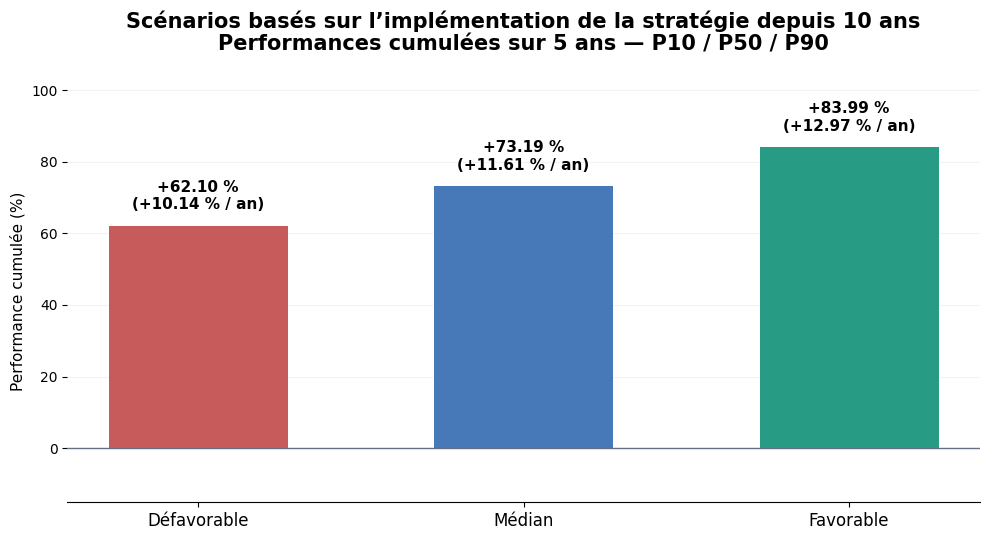

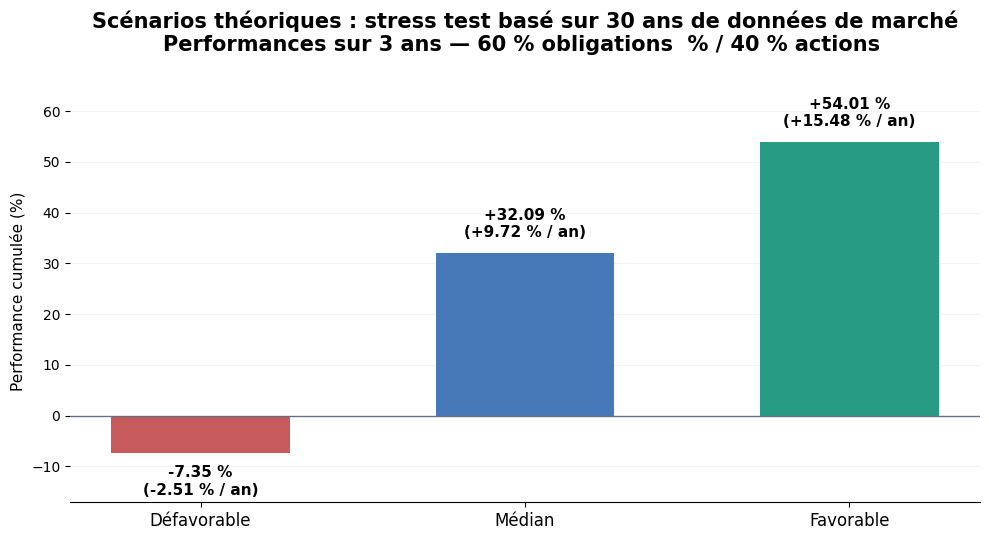

In [207]:

import matplotlib.pyplot as plt
import numpy as np

def exporter_bar_chart(df, titre, sous_titre, fichier):
    # Première colonne = performance cumulée
    performances = df.iloc[:, 0] * 100
    labels = df.index.astype(str)
    annualisees = df["Annualisée"] * 100

    couleurs = ["#C75B5B", "#4778B8", "#279B83"]

    fig, ax = plt.subplots(figsize=(10, 5.5))

    x = np.arange(len(df))
    bars = ax.bar(
        x, performances,
        color=couleurs[:len(df)],
        width=0.55
    )

    ax.axhline(0, color="#667085", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=12)
    ax.set_ylabel("Performance cumulée (%)", fontsize=11)

    # Étiquettes des performances
    amplitude = max(abs(performances).max(), 1)
    marge = amplitude * 0.045

    for bar, perf, annualisee in zip(
        bars, performances, annualisees
    ):
        y = perf + marge if perf >= 0 else perf - marge

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            y,
            f"{perf:+.2f} %\n({annualisee:+.2f} % / an)",
            ha="center",
            va="bottom" if perf >= 0 else "top",
            fontsize=11,
            fontweight="bold"
        )

    ax.set_ylim(
        min(0, performances.min()) - amplitude * 0.18,
        max(0, performances.max()) + amplitude * 0.22
    )

    ax.set_title(
        titre + "\n" + sous_titre,
        fontsize=15,
        fontweight="bold",
        pad=22
    )

    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

    fig.tight_layout()
    fig.savefig(
        fichier,
        dpi=250,
        format="jpeg",
        bbox_inches="tight",
        facecolor="white"
    )
    plt.show()
    plt.close(fig)



from pathlib import Path

Path("results").mkdir(parents=True, exist_ok=True)

exporter_bar_chart(
    scenarios_5y,
    "Scénarios basés sur l’implémentation de la stratégie depuis 10 ans",
    "Performances cumulées sur 5 ans — P10 / P50 / P90",
    "results/scenarios_historiques_5_ans.jpeg"
)

exporter_bar_chart(
    scenarios,
    "Scénarios théoriques : stress test basé sur 30 ans de données de marché",
    "Performances sur 3 ans — 60 % obligations  % / 40 % actions ",
    "results/scenarios_prospectifs_3_ans.jpeg"
)



# 4. PORTFOLIO WEIGHTS OPTIMIZATION

In [ ]:
portfolio_daily_returns_opt=daily_returns_etf.drop(columns='EURUSD')

# Define the risk-free rate (adjust to your data)
risk_free_rate = 0.0

# Calculate mean returns and covariance matrix
mean_returns = portfolio_daily_returns_opt.mean()
cov_matrix = portfolio_daily_returns_opt.cov()

# Number of assets
num_assets = len(portfolio_daily_returns_opt.columns)

# Initial guess for weights
initial_weights = np.array([1 / num_assets] * num_assets)

# Define portfolio return and volatility
def portfolio_performance(weights, mean_returns, cov_matrix):
    portfolio_return = np.sum(weights * mean_returns)
    portfolio_volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    return portfolio_return, portfolio_volatility

# Objective function: negative Sharpe ratio
def negative_sharpe_ratio(weights, mean_returns, cov_matrix, risk_free_rate):
    portfolio_return, portfolio_volatility = portfolio_performance(weights, mean_returns, cov_matrix)
    sharpe_ratio = (portfolio_return - risk_free_rate) / portfolio_volatility
    return -sharpe_ratio

# Constraints: weights sum to 1
constraints = ({'type': 'eq', 'fun': lambda weights: np.sum(weights) - 1})

# Bounds: weights between 0 and 1
bounds = tuple((0, 1) for _ in range(num_assets))

# Optimize weights
result = minimize(
    fun=negative_sharpe_ratio,
    x0=initial_weights,
    args=(mean_returns, cov_matrix, risk_free_rate),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

# Extract optimal weights
optimal_weights = result.x

# Display results
print("Optimal Weights:", optimal_weights)
print("Maximum Sharpe Ratio:", -result.fun)


# 5. ANALYSE JP MORGAN STRATEGY

In [168]:
#jp_opcvm_hist = yf.Ticker("0P0001K15I").history(period="3y")

#print("Nombre de lignes :", len(jp_opcvm_hist))
#display(jp_opcvm_hist.head())

#  FINALEMENT ON TELECHARGE DEPUIS INVESTING https://fr.investing.com/funds/lu1283473053-historical-data

Failed to get ticker '0P0001K15I' reason: Expecting value: line 1 column 1 (char 0)
0P0001K15I: No price data found, symbol may be delisted (period=3y)


Nombre de lignes : 0


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,


In [170]:
strategy_excel = reload_strategy_excel()

jp_opcvm_hist = pd.read_excel(
    strategy_excel,
    sheet_name='JPMORGAN',
    usecols="A:B"
)

jp_opcvm_hist.columns = ['Date', 'JP_OPCVM']

jp_opcvm_hist['Date'] = pd.to_datetime(
    jp_opcvm_hist['Date'],
    dayfirst=True
)

jp_opcvm_hist['JP_OPCVM'] = pd.to_numeric(
    jp_opcvm_hist['JP_OPCVM'],
    errors='coerce'
)

jp_opcvm_hist = jp_opcvm_hist.sort_values('Date').reset_index(drop=True)
jp_opcvm_hist['ref_index'] = (
    100 * jp_opcvm_hist['JP_OPCVM'] / jp_opcvm_hist['JP_OPCVM'].iloc[0]
)

display(jp_opcvm_hist.head())

STRATEGY_ANALYSIS rechargé avec succès


,Date,JP_OPCVM,ref_index
0,2017-05-10,104.98,100.000000
1,2017-05-17,104.90,99.923795
2,2017-05-24,104.66,99.695180
3,2017-05-31,104.88,99.904744
4,2017-06-07,105.11,100.123833


,Date,JP_OPCVM,ref_index
0,2017-05-10,104.98,100.000000
1,2017-05-17,104.90,99.923795
2,2017-05-24,104.66,99.695180
3,2017-05-31,104.88,99.904744
4,2017-06-07,105.11,100.123833


In [171]:
# Rendements entre deux valeurs liquidatives
r = jp_opcvm_hist['JP_OPCVM'].pct_change(fill_method=None).dropna()

N = 52

jp_analytics = pd.DataFrame({
    'Mean annualisé': [(1 + r.mean())**N - 1],
    'Median annualisé': [(1 + r.median())**N - 1],
    'Vol annualisée': [r.std() * np.sqrt(N)],
    'CAGR': [(jp_opcvm_hist['JP_OPCVM'].iloc[-1] /
              jp_opcvm_hist['JP_OPCVM'].iloc[0]) **
             (365.25 / (jp_opcvm_hist['Date'].iloc[-1] -
                        jp_opcvm_hist['Date'].iloc[0]).days) - 1]
}, index=['JPMORGAN'])

display(jp_analytics.style.format("{:.2%}"))

,Mean annualisé,Median annualisé,Vol annualisée,CAGR
JPMORGAN,2.21%,4.47%,4.82%,2.48%


Début : 2017-05-12
Fin   : 2026-10-16
Nombre de points : 492


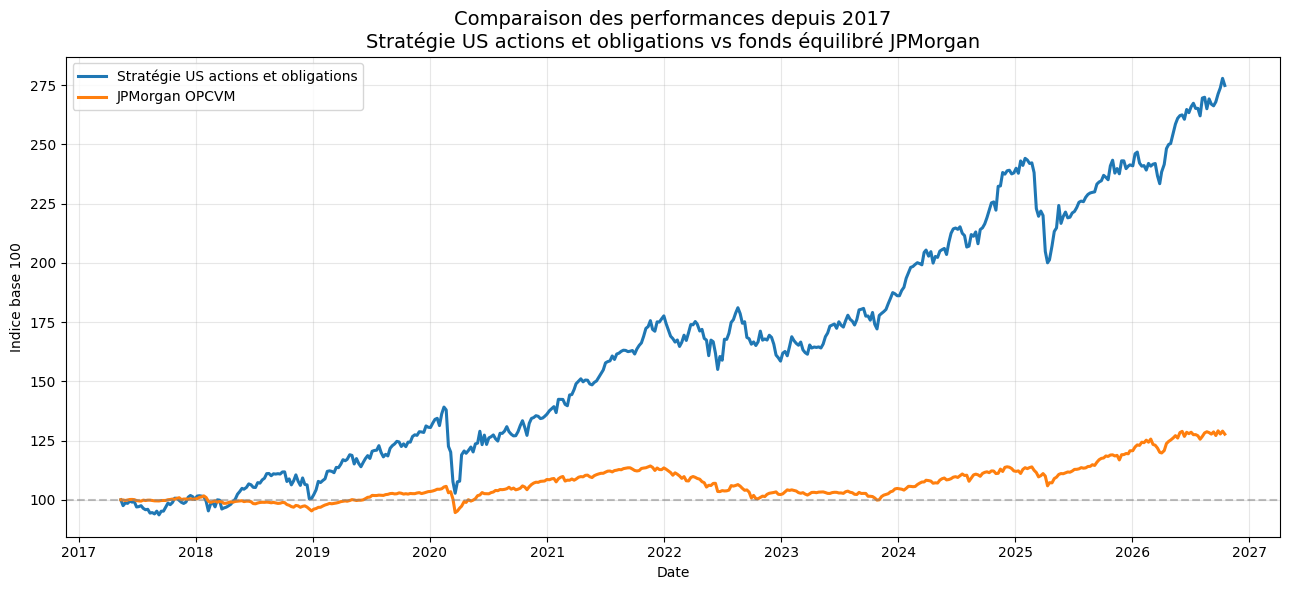


Fichiers enregistrés :
PNG : /Users/alamazou/code/d1quant/gestion_patrimoine/results/comparaison_portfolio_jpmorgan.png (322,478 octets)
PDF : /Users/alamazou/code/d1quant/gestion_patrimoine/results/comparaison_portfolio_jpmorgan.pdf (26,413 octets)


In [182]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# =====================================================
# 1. PRÉPARER LES DEUX INDICES
# =====================================================

port = portfolio_index[['Date', 'ref_index']].copy()
jp = jp_opcvm_hist[['Date', 'ref_index']].copy()

port.columns = ['Date', 'Portfolio']
jp.columns = ['Date', 'JPMorgan']

# Convertir et normaliser les dates
port['Date'] = pd.to_datetime(port['Date']).dt.normalize()
jp['Date'] = pd.to_datetime(jp['Date']).dt.normalize()

# Supprimer les valeurs manquantes
port = port.dropna().sort_values('Date')
jp = jp.dropna().sort_values('Date')

# Éliminer les dates en double
port = port.drop_duplicates('Date', keep='last')
jp = jp.drop_duplicates('Date', keep='last')

# =====================================================
# 2. ALIGNER LES DATES
# =====================================================

# Ne garder que la période commune
start_date = max(port['Date'].min(), jp['Date'].min())
end_date = min(port['Date'].max(), jp['Date'].max())

port = port[
    (port['Date'] >= start_date) &
    (port['Date'] <= end_date)
].copy()

# Aligner les VL JPMorgan sur les dates du portefeuille
comparison = pd.merge_asof(
    port,
    jp,
    on='Date',
    direction='backward',
    tolerance=pd.Timedelta(days=7)
)

comparison = comparison.dropna().reset_index(drop=True)

if comparison.empty:
    raise ValueError("Aucune date commune trouvée entre les deux indices.")

# =====================================================
# 3. REBASER LES DEUX INDICES À 100
# =====================================================

comparison['Portfolio'] = (
    100 * comparison['Portfolio'] /
    comparison['Portfolio'].iloc[0]
)

comparison['JPMorgan'] = (
    100 * comparison['JPMorgan'] /
    comparison['JPMorgan'].iloc[0]
)

print("Début :", comparison['Date'].iloc[0].date())
print("Fin   :", comparison['Date'].iloc[-1].date())
print("Nombre de points :", len(comparison))

# =====================================================
# 4. CRÉER LE GRAPHIQUE
# =====================================================

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    comparison['Date'],
    comparison['Portfolio'],
    label='Stratégie US actions et obligations',
    linewidth=2.2
)

ax.plot(
    comparison['Date'],
    comparison['JPMorgan'],
    label='JPMorgan OPCVM',
    linewidth=2.2
)

ax.axhline(
    100,
    color='gray',
    linestyle='--',
    alpha=0.5
)

ax.set_title(
    'Comparaison des performances depuis 2017\n'
    'Stratégie US actions et obligations vs fonds équilibré JPMorgan',
    fontsize=14
)

ax.set_xlabel('Date')
ax.set_ylabel('Indice base 100')

ax.legend(loc='upper left')
ax.grid(alpha=0.3)

fig.tight_layout()

# =====================================================
# 5. ENREGISTRER DANS RESULTS
# =====================================================

results_dir = Path.cwd() / 'results'
results_dir.mkdir(parents=True, exist_ok=True)

png_file = results_dir / 'comparaison_portfolio_jpmorgan.png'
pdf_file = results_dir / 'comparaison_portfolio_jpmorgan.pdf'

# Sauvegarder AVANT plt.show()
fig.savefig(
    png_file,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

fig.savefig(
    pdf_file,
    bbox_inches='tight',
    facecolor='white'
)

# =====================================================
# 6. AFFICHER ET VÉRIFIER
# =====================================================

plt.show()

print("\nFichiers enregistrés :")
print(f"PNG : {png_file} ({png_file.stat().st_size:,} octets)")
print(f"PDF : {pdf_file} ({pdf_file.stat().st_size:,} octets)")